# Back to the data itself: outliers in ML datasets

**Idea.** A global ±3σ rule treats every point far from the mean the same way, and in doing so it quietly encodes our expectations of what "normal" should look like. Unsupervised ML can learn the structure of the data instead of imposing one.

This notebook compares three ways of deciding what an outlier is, on the **same simulated two-channel sensor dataset**:

| | Method | What it does |
|---|---|---|
| **A** | Global ±3σ rule | Judges each channel independently against the spread of the whole dataset |
| **B** | DBSCAN | Finds dense groups; points in no dense group are "isolated". Its radius ε is set from the **sensor noise** |
| **C** | Autoencoder | Learns a low-dimensional description of the data; poorly reconstructed points get a high score |

**Take-away.** These methods surface *candidates*. They tell you a point is unusual. Sensor physics and noise characterisation tell you what it *means*, so flag and record, don't delete silently.

> All data here is **simulated** with a fixed random seed, so the results are reproducible.

**Requirements:** `numpy`, `matplotlib`, `seaborn`, `scikit-learn`

## 1. Imports

In [5]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

## 2. Configuration

`SENSOR_SIGMA` is the standard deviation of the sensor's measurement noise. In a real project this comes from the **instrument specification or a dedicated noise characterisation** (e.g. repeated measurements of a stable signal). Everything that follows is anchored to this number.

In [6]:
SEED = 42                 # fixes the simulation, so the figure is reproducible
SENSOR_SIGMA = 0.5        # measurement noise of the sensor (same units as the channels)
OUTPUT_FIG = Path("outlier_unsupervised_vs_3sigma.png")   # saved next to the notebook

rng = np.random.default_rng(SEED)

## 3. Simulate the data

Two sensor channels measure a system with **two operating regimes**. Both lie along a common trend (a 1-D structure in the 2-D channel space), with scatter perpendicular to the trend at roughly the sensor-noise level.

On top of that we add:

- a **small but coherent group** of 14 rare events, tightly clustered, away from the main trend. Think of a rare fault mode or a small anomaly. This is the "signal" that a blunt filter may delete.
- **8 isolated points** scattered uniformly, which behave like sporadic glitches.

The ground-truth labels (`truth`) are used only for reporting, never by the methods.

In [7]:
# Direction along the trend (u) and perpendicular to it (v)
u = np.array([1.0, 0.65])
u /= np.linalg.norm(u)
v = np.array([-u[1], u[0]])


def regime(n, center, along, perp):
    """Points scattered along the trend (std = `along`) and across it (std = `perp`)."""
    t = rng.normal(0, along, n)[:, None]
    p = rng.normal(0, perp, n)[:, None]
    return np.asarray(center) + t * u + p * v


reg_a = regime(330, [0.0, 0.0], along=0.9, perp=0.5)    # operating regime A
reg_b = regime(130, [6.0, 3.9], along=0.8, perp=0.5)    # operating regime B

# small, tightly clustered group of rare events (isolated from the main trend)
rare = np.asarray([13.5, -5.5]) + rng.normal(0, 0.28, (14, 2))

# sporadic isolated points, uniform over the plane
sparse = np.column_stack([rng.uniform(-5, 15, 8), rng.uniform(-8, 8, 8)])

# Stack everything and keep ground-truth labels for reporting only
X = np.vstack([reg_a, reg_b, rare, sparse])
truth = np.array(["A"] * len(reg_a) + ["B"] * len(reg_b)
                 + ["rare"] * len(rare) + ["sparse"] * len(sparse))

print(f"Dataset: {X.shape[0]} samples x {X.shape[1]} channels")
for t in ["A", "B", "rare", "sparse"]:
    print(f"  {t:>6}: {(truth == t).sum()} points")

Dataset: 482 samples x 2 channels
       A: 330 points
       B: 130 points
    rare: 14 points
  sparse: 8 points


## 4. Method A: global ±3σ rule

The classic recipe: compute the mean and standard deviation of **each channel across the whole dataset**, and flag any point more than 3σ away on **either** channel.

Two weaknesses are visible later in the figure:

1. σ is computed from the data itself, including the regimes and the rare events. The threshold reflects our dataset's spread, not the sensor's physics.
2. Each channel is judged independently, so the structure *between* channels and between groups is ignored.

In [8]:
mu, sd = X.mean(axis=0), X.std(axis=0)
z = (X - mu) / sd                       # per-channel z-scores
flag_3s = (np.abs(z) > 3).any(axis=1)   # True if beyond 3 sigma on either channel

n_rare_removed = int(((truth == "rare") & flag_3s).sum())
print(f"3-sigma rule flags {flag_3s.sum()} points, "
      f"including {n_rare_removed}/{(truth == 'rare').sum()} of the rare events")

3-sigma rule flags 15 points, including 14/14 of the rare events


## 5. Method B: DBSCAN with ε grounded in the sensor noise

DBSCAN groups points that are densely packed and labels everything else as noise (`-1`). It has two parameters:

- `eps` (ε): the neighbourhood radius.
- `min_samples`: how many neighbours make a point part of a dense region.

Instead of tuning ε by eye, we set it from the physics: **ε = 3 × sensor σ**. Points closer than about three noise-widths are considered to be "the same kind of measurement". This is where reliable **noise characterisation** matters: a wrong `SENSOR_SIGMA` gives a wrong ε.

In [9]:
db = DBSCAN(eps=3 * SENSOR_SIGMA, min_samples=6).fit(X)
labels = db.labels_                       # -1 = isolated, 0..k = dense groups

cluster_ids = [l for l in sorted(set(labels)) if l != -1]
cluster_sizes = {l: int((labels == l).sum()) for l in cluster_ids}

print(f"DBSCAN found {len(cluster_ids)} dense groups with sizes {list(cluster_sizes.values())}")
print(f"and {(labels == -1).sum()} isolated points")

# How do the isolated points relate to the ground truth? (reporting only)
print("Isolated points by true origin:",
      {t: int(((labels == -1) & (truth == t)).sum()) for t in ["A", "B", "rare", "sparse"]})

DBSCAN found 3 dense groups with sizes [331, 131, 15]
and 5 isolated points
Isolated points by true origin: {'A': 0, 'B': 0, 'rare': 0, 'sparse': 5}


## 6. Method C: autoencoder (bottleneck neural network)

An autoencoder is trained to **reproduce its input** after squeezing it through a narrow bottleneck. Data that follows the dominant structure is reconstructed well. Points that don't follow it are reconstructed poorly, giving a **graded outlier score** (the reconstruction error) instead of a yes/no cut.

Here the autoencoder is a small `MLPRegressor` with a **1-unit bottleneck** (`4 -> 1 -> 4` hidden units), trained to map the standardised data onto itself.

**Two practical notes**

- Small networks can converge to poor solutions, so we train several seeds and keep the one with the lowest training loss.
- **Capacity matters.** In testing, a larger network with a bigger bottleneck learned to reconstruct the rare group as well, so it stopped being flagged. An autoencoder trained on data containing a rare group can absorb it if it has enough capacity. Treat the score as a ranking, not a verdict.

In [10]:
Xs = StandardScaler().fit_transform(X)    # standardise so both channels count equally

best = None
for seed in range(12):
    model = MLPRegressor(
        hidden_layer_sizes=(4, 1, 4),     # encoder 4 -> bottleneck 1 -> decoder 4
        activation="tanh",
        alpha=1e-3,                       # small L2 regularisation
        max_iter=6000,
        learning_rate_init=0.005,
        random_state=seed,
    ).fit(Xs, Xs)                         # input = target: learn to reconstruct
    if best is None or model.loss_ < best.loss_:
        best = model
ae = best

# reconstruction error per sample = distance between input and its reconstruction
err = np.linalg.norm(Xs - ae.predict(Xs), axis=1)

print("Mean reconstruction error by true origin:")
for t in ["A", "B", "rare", "sparse"]:
    print(f"  {t:>6}: {err[truth == t].mean():.2f}")

Mean reconstruction error by true origin:
       A: 0.15
       B: 0.21
    rare: 0.33
  sparse: 1.06


## 7. Summary of the three methods

Reading the numbers before looking at the figure:

- **3σ rule:** removes the rare group (it sits beyond the global 3σ bounds) and misses isolated points that lie inside the bounds.
- **DBSCAN:** keeps the rare group as its own small but coherent cluster, separate from the two regimes, and labels the sporadic points as isolated.
- **Autoencoder:** gives the isolated points the highest scores, the rare group an intermediate score, and normal data the lowest.

In [11]:
n_missed = int(((labels == -1) & ~flag_3s).sum())

print(f"A  3-sigma    : removed {flag_3s.sum()} points "
      f"({n_rare_removed}/{(truth == 'rare').sum()} rare events); "
      f"missed {n_missed} isolated points inside the bounds")
print(f"B  DBSCAN     : {len(cluster_ids)} dense groups "
      f"(sizes {list(cluster_sizes.values())}), {(labels == -1).sum()} isolated points")
print(f"C  Autoencoder: mean error rare {err[truth == 'rare'].mean():.2f} | "
      f"normal {err[np.isin(truth, ['A', 'B'])].mean():.2f} | "
      f"sparse {err[truth == 'sparse'].mean():.2f}")

A  3-sigma    : removed 15 points (14/14 rare events); missed 5 isolated points inside the bounds
B  DBSCAN     : 3 dense groups (sizes [331, 131, 15]), 5 isolated points
C  Autoencoder: mean error rare 0.33 | normal 0.17 | sparse 1.06


## 8. Figure

Three panels, same data, shared axes:

- **A:** the ±3σ bounds (shaded) and the points they remove (red rings).
- **B:** DBSCAN groups in colour, isolated points as grey crosses. The black bar shows the size of ε in data units.
- **C:** points coloured and sized by autoencoder reconstruction error.

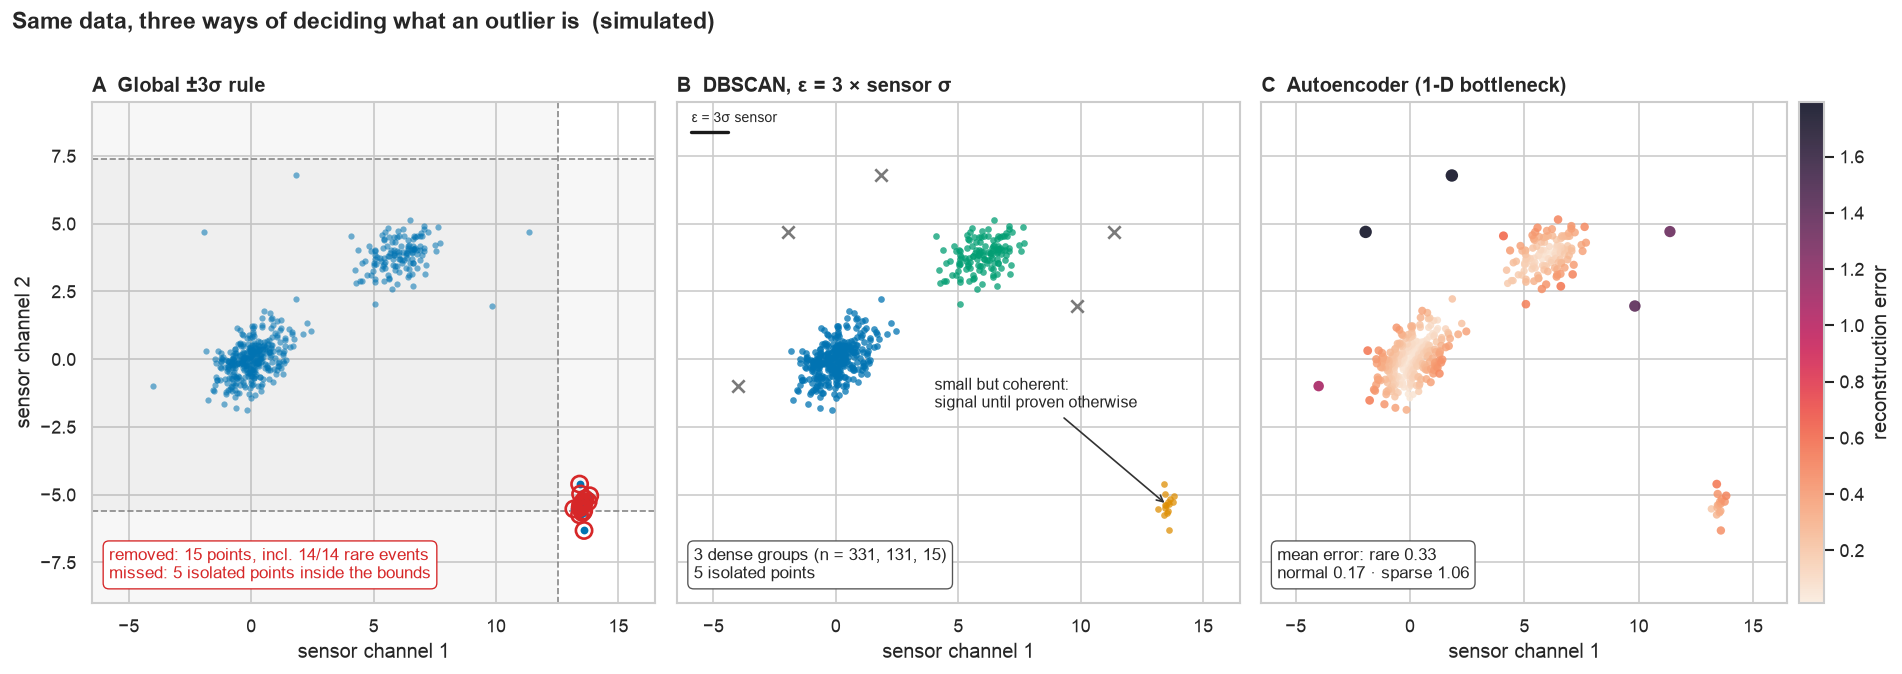

Saved figure to /Users/faroughrahimzadeh/Desktop/Python_Code/LinkedIn/Outlier_detection_post/outlier_unsupervised_vs_3sigma.png


In [12]:
sns.set_theme(style="whitegrid", context="notebook")
pal = sns.color_palette("colorblind")
c_a, c_b, c_rare, c_noise, c_red = pal[0], pal[2], pal[1], "#7a7a7a", "#d62728"

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), dpi=120, sharex=True, sharey=True)
for ax in axes:
    ax.set_xlabel("sensor channel 1")
    ax.set_xlim(-6.5, 16.5)
    ax.set_ylim(-9, 9.5)
axes[0].set_ylabel("sensor channel 2")

# ---- Panel A: global 3-sigma rule -------------------------------------
ax = axes[0]
ax.axvspan(mu[0] - 3 * sd[0], mu[0] + 3 * sd[0], color="#999", alpha=0.08, lw=0)
ax.axhspan(mu[1] - 3 * sd[1], mu[1] + 3 * sd[1], color="#999", alpha=0.08, lw=0)
for val in (mu[0] - 3 * sd[0], mu[0] + 3 * sd[0]):
    ax.axvline(val, ls="--", c="#888", lw=1)
for val in (mu[1] - 3 * sd[1], mu[1] + 3 * sd[1]):
    ax.axhline(val, ls="--", c="#888", lw=1)
ax.scatter(*X[~flag_3s].T, s=14, color=c_a, alpha=0.55, lw=0)
ax.scatter(*X[flag_3s].T, s=22, color=c_a, lw=0, zorder=3)
ax.scatter(*X[flag_3s].T, s=95, facecolors="none", edgecolors=c_red, lw=1.6, zorder=4)
ax.set_title("A  Global ±3σ rule", loc="left", fontweight="bold")
ax.text(0.03, 0.04,
        f"removed: {flag_3s.sum()} points, incl. {n_rare_removed}/{(truth == 'rare').sum()} rare events\n"
        f"missed: {n_missed} isolated points inside the bounds",
        transform=ax.transAxes, fontsize=10, color=c_red, va="bottom",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=c_red, lw=0.8))

# ---- Panel B: DBSCAN ----------------------------------------------------
ax = axes[1]
smallest = min(cluster_sizes, key=cluster_sizes.get)            # the small coherent group
bigger = sorted([l for l in cluster_ids if l != smallest], key=lambda l: -cluster_sizes[l])
colors = {smallest: c_rare}
colors.update({l: c for l, c in zip(bigger, [c_a, c_b, pal[4], pal[5]])})
for l in cluster_ids:
    ax.scatter(*X[labels == l].T, s=16, color=colors[l], alpha=0.75, lw=0)
ax.scatter(*X[labels == -1].T, s=55, marker="x", color=c_noise, lw=1.6, zorder=4)
ax.set_title("B  DBSCAN, ε = 3 × sensor σ", loc="left", fontweight="bold")
ax.text(0.03, 0.04,
        f"{len(cluster_ids)} dense groups (n = {', '.join(str(cluster_sizes[l]) for l in bigger)}, "
        f"{cluster_sizes[smallest]})\n{(labels == -1).sum()} isolated points",
        transform=ax.transAxes, fontsize=10, va="bottom",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#555", lw=0.8))
cx, cy = X[labels == smallest].mean(axis=0)
ax.annotate("small but coherent:\nsignal until proven otherwise",
            xy=(cx, cy), xytext=(cx - 9.5, cy + 3.6), fontsize=9.5,
            arrowprops=dict(arrowstyle="->", color="#333", lw=1))
ax.plot([-5.9, -5.9 + 3 * SENSOR_SIGMA], [8.4, 8.4], c="k", lw=2)   # scale bar = eps
ax.text(-5.9, 8.75, "ε = 3σ sensor", ha="left", fontsize=8.5)

# ---- Panel C: autoencoder ----------------------------------------------
ax = axes[2]
order = np.argsort(err)                                   # draw high errors last (on top)
sc = ax.scatter(*X[order].T, c=err[order], s=16 + 40 * (err[order] / err.max()),
                cmap="rocket_r", alpha=0.85, lw=0)
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02)
cb.set_label("reconstruction error")
ax.set_title("C  Autoencoder (1-D bottleneck)", loc="left", fontweight="bold")
ax.text(0.03, 0.04,
        f"mean error: rare {err[truth == 'rare'].mean():.2f}\n"
        f"normal {err[np.isin(truth, ['A', 'B'])].mean():.2f} · sparse {err[truth == 'sparse'].mean():.2f}",
        transform=ax.transAxes, fontsize=10, va="bottom",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#555", lw=0.8))

fig.suptitle("Same data, three ways of deciding what an outlier is  (simulated)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT_FIG, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved figure to {OUTPUT_FIG.resolve()}")

## 9. Interpretation and caveats

**What the figure shows**

- The ±3σ rule removed the small coherent group, which in a real setting could be a rare fault mode, and it missed isolated points that sat inside its bounds.
- DBSCAN distinguished three situations the rule cannot: two dense operating regimes, a small but coherent group, and isolated points. These deserve different treatment (keep, investigate, or discard as glitches).
- The autoencoder gave a graded score. It ranks points but doesn't say what they are.

**Caveats worth keeping in mind**

- **These are simulated data.** Real data is messier: regimes overlap, noise is not exactly Gaussian, and drift exists.
- **Every method has assumptions and parameters.** DBSCAN depends on `eps` and `min_samples`. An autoencoder depends on its architecture, training data, and capacity (see section 6). "Unsupervised" does not mean "assumption-free".
- **ε is only as good as the noise characterisation.** If `SENSOR_SIGMA` is wrong, DBSCAN's notion of "isolated" is wrong too.
- **Unusual does not mean wrong.** A high score means a point is rare. Whether it is a glitch, a fault, or a discovery is a question for the physics and the domain, not for the algorithm.

**Practical workflow**

1. Characterise the sensor noise first.
2. Use unsupervised methods to surface and group candidates.
3. Inspect the groups, especially the small coherent ones, using domain knowledge.
4. **Don't delete silently.** Record why each point was kept or removed.

## 10. Things to try

- Change `SENSOR_SIGMA` (e.g. 0.3 or 1.0) and see how DBSCAN's grouping changes.
- Vary `min_samples` and observe when the small group merges into noise.
- Increase the autoencoder to `hidden_layer_sizes=(16, 2, 16)` and watch the rare group's score drop as the network absorbs it.
- Try `IsolationForest` or `LocalOutlierFactor` from scikit-learn as additional panels.